# Advanced GINE + Frozen ESM-2 Drug–Target Affinity Prediction

This notebook evaluates the advanced drug–target affinity model on the **DAVIS** dataset.

The model extends the baseline experiments in three main ways:

- the drug encoder uses **GINE**, allowing chemical bond features to participate in message passing;
- protein sequences are represented using **frozen ESM-2 residue embeddings** followed by a task-specific 1D CNN;
- atom and residue representations interact through **bidirectional cross-attention** before pooling and affinity regression.

The advanced model is evaluated using the same three settings used for the DAVIS baselines:

- Random split
- Cold-drug split
- Cold-target split

DAVIS is used for the main advanced experiment so that the advanced architecture can be compared directly with the DAVIS GCN + CNN, GAT + CNN, and GIN + CNN baselines.

## Notebook workflow

```text
Drug SMILES                                      Protein AA Sequence
     │                                                   │
     ▼                                                   ▼
RDKit molecular graph                              Frozen ESM-2
atoms + bond features                              residue embeddings
     │                                                   │
     ▼                                                   ▼
4-layer GINE                                       projection to 128
Residual + LayerNorm                                    │
     │                                                   ▼
     │                                             3-layer 1D CNN
     │                                             kernels 7, 5, 3
     ▼                                                   ▼
Atom representations                              Residue representations
[B, N_atoms, 128]                                 [B, L, 128]
     │                                                   │
     └──────────────────────┬────────────────────────────┘
                            ▼
                Bidirectional Cross-Attention
                  atoms query residues
                  residues query atoms
                  MHA + residual + norm + FFN
                            │
              ┌─────────────┴─────────────┐
              ▼                           ▼
      Updated atom features       Updated residue features
              │                           │
              ▼                           ▼
      Attention pooling           Attention pooling
              │                           │
              ▼                           ▼
       Drug vector [B,128]       Protein vector [B,128]
              └─────────────┬─────────────┘
                            ▼
                      Concatenate
                        [B,256]
                            │
                            ▼
                    MLP regressor
                   256 → 512 → 256 → 1
                            │
                            ▼
                       Predicted pKd
                            │
          ┌─────────────────┼──────────────────┐
          ▼                 ▼                  ▼
       Random          Cold-drug          Cold-target
          │                 │                  │
          ▼                 ▼                  ▼
        Train / validate / test with early stopping
          │                 │                  │
          └─────────────────┼──────────────────┘
                            ▼
                  MSE, RMSE, MAE, CI, Pearson
                            │
                            ▼
                Save checkpoints, predictions,
                     figures and metrics
```

Frozen ESM-2 is used only as a feature extractor. Each unique DAVIS protein is embedded once and the residue representations are cached for reuse during training.

In [2]:
# ============================================================
# COLAB SETUP — DRIVE + GITHUB + PERMANENT RESULTS
# ============================================================

from google.colab import drive, userdata
from pathlib import Path

import base64
import os
import shutil
import subprocess
import torch


# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

drive.mount("/content/drive", force_remount=False)


# ------------------------------------------------------------
# 2. Project settings
# ------------------------------------------------------------

GITHUB_REPO = "https://github.com/Thebluesky303/msc-dissertation-drug-repurposing.git"

BRANCH = "final-aml-gnn-dta"

REPO_DIR = Path("/content/final-msc-dissertation-drug-repurposing")

DRIVE_PROJECT = Path("/content/drive/MyDrive/final-msc-dissertation-drug-repurposing")

DRIVE_RESULTS = DRIVE_PROJECT / "results"


# ------------------------------------------------------------
# 3. Create permanent Drive folders
# ------------------------------------------------------------

result_folders = [
    "metrics",
    "predictions",
    "figures",
    "checkpoints",
    "esm_embeddings",
    "validation",
    "validation_cache",
]

DRIVE_PROJECT.mkdir(parents=True, exist_ok=True)
DRIVE_RESULTS.mkdir(parents=True, exist_ok=True)

for folder_name in result_folders:
    (DRIVE_RESULTS / folder_name).mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 4. Read GitHub token from Colab Secrets
# ------------------------------------------------------------

token = userdata.get("colab-dissertation")

if not token:
    raise ValueError("GITHUB_TOKEN was not found in Colab Secrets.")

auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()
git_auth = f"AUTHORIZATION: basic {auth}"


# ------------------------------------------------------------
# 5. Clone repository if it does not exist
#    Otherwise update the existing clone
# ------------------------------------------------------------

if not (REPO_DIR / ".git").exists():
    print("Cloning repository...")

    subprocess.run(
        [
            "git",
            "-c", f"http.extraheader={git_auth}",
            "clone",
            "--branch", BRANCH,
            "--single-branch",
            GITHUB_REPO,
            str(REPO_DIR),
        ],
        check=True,
    )

else:
    print("Repository already exists.")

    subprocess.run(
        ["git", "-C", str(REPO_DIR), "-c", f"http.extraheader={git_auth}", "fetch", "origin", BRANCH],
        check=True,
    )

    subprocess.run(
        ["git", "-C", str(REPO_DIR), "switch", BRANCH],
        check=True,
    )

    subprocess.run(
        ["git", "-C", str(REPO_DIR), "-c", f"http.extraheader={git_auth}", "pull", "--ff-only", "origin", BRANCH],
        check=True,
    )


# ------------------------------------------------------------
# 6. Connect repo/results directly to Google Drive
# ------------------------------------------------------------

LOCAL_RESULTS = REPO_DIR / "results"

if LOCAL_RESULTS.is_symlink():
    current_target = LOCAL_RESULTS.resolve()

    if current_target != DRIVE_RESULTS.resolve():
        LOCAL_RESULTS.unlink()

elif LOCAL_RESULTS.exists():
    # Copy any existing local results before replacing
    # the folder with the Drive link.
    for item in LOCAL_RESULTS.iterdir():
        destination = DRIVE_RESULTS / item.name

        if item.is_dir():
            shutil.copytree(item, destination, dirs_exist_ok=True)
        else:
            shutil.copy2(item, destination)

    shutil.rmtree(LOCAL_RESULTS)


if not LOCAL_RESULTS.exists():
    os.symlink(DRIVE_RESULTS, LOCAL_RESULTS, target_is_directory=True)


# ------------------------------------------------------------
# 7. Move into repository
# ------------------------------------------------------------

os.chdir(REPO_DIR)


# ------------------------------------------------------------
# 8. Final checks
# ------------------------------------------------------------

branch = subprocess.check_output(["git", "branch", "--show-current"], text=True).strip()
commit = subprocess.check_output(["git", "log", "-1", "--oneline"], text=True).strip()

print()
print("=" * 65)
print("COLAB PROJECT READY")
print("=" * 65)

print("Repository:", REPO_DIR)
print("Branch:", branch)
print("Commit:", commit)
print("Results saved to Drive:", LOCAL_RESULTS.resolve())
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("=" * 65)


# Install project dependencies for this Colab runtime

%cd /content/final-msc-dissertation-drug-repurposing

!pip install -q -r requirements.txt

print("Project requirements installed.")

import torch
import torch_geometric
import rdkit
import transformers
import pandas
import numpy

print("PyTorch:", torch.__version__)
print("PyG:", torch_geometric.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Environment ready.")

Mounted at /content/drive
Cloning repository...

COLAB PROJECT READY
Repository: /content/final-msc-dissertation-drug-repurposing
Branch: final-aml-gnn-dta
Commit: e6fbaaa Modify GINE MLP to use doubled hidden dimension
Results saved to Drive: /content/drive/MyDrive/final-msc-dissertation-drug-repurposing/results
CUDA available: True
GPU: NVIDIA A100-SXM4-80GB
/content
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 50.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 72.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 129.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 133.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 915.3/915.3 kB 58.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.8/59.8 kB 6.5 MB/s eta 0:00:

# Part A — Setup and DAVIS preparation

## 1. Imports

In [3]:
import gc
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from torch.utils.data import DataLoader
from transformers import AutoModel, AutoTokenizer

## 2. Locate the project folder

In [4]:
def find_project_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path("/content/final_aml_gnn_dta"),
    ]

    content_dir = Path("/content")
    if content_dir.exists():
        candidates.extend(
            path.parent
            for path in content_dir.glob("*/config.py")
        )

    for candidate in candidates:
        if (
            (candidate / "config.py").exists()
            and (candidate / "src").exists()
        ):
            return candidate.resolve()

    raise FileNotFoundError(
        "Project root could not be found. "
        "Run this notebook from final_aml_gnn_dta or clone/copy "
        "the project into the current environment."
    )


PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /content/final-msc-dissertation-drug-repurposing


## 3. Project settings and shared functions

The advanced model uses the same DAVIS data splits, random seed, maximum epochs, early-stopping behaviour, loss function, and evaluation metrics as the baseline experiments.

A smaller training batch size is used because cross-attention retains atom-level and residue-level representations.

In [5]:
from config import (
    CHECKPOINTS_DIR,
    DAVIS_DIR,
    FIGURES_DIR,
    LEARNING_RATE,
    MAX_EPOCHS,
    MAX_PROTEIN_LENGTH,
    METRICS_DIR,
    PREDICTIONS_DIR,
    RANDOM_SEED,
    RESULTS_DIR,
    TRAIN_RATIO,
    VALIDATION_RATIO,
    TEST_RATIO,
)

from src.models import (
    AdvancedDTAModel,
    count_trainable_parameters,
)

from src.preprocessing import (
    ATOM_FEATURE_DIM,
    BOND_FEATURE_DIM,
    AdvancedInteractionDataset,
    advanced_collate_fn,
    build_drug_graph_cache,
    build_esm_embedding_cache,
    check_cold_split,
    check_esm_embedding_cache,
    cold_drug_split,
    cold_target_split,
    load_deepdta_dataset,
    load_esm_embedding_cache,
    random_split,
    save_esm_embedding_cache,
)

from src.training import (
    evaluate_model,
    fit_model,
)

from src.utils import (
    get_device,
    save_predictions_csv,
    set_seed,
)

set_seed(RANDOM_SEED)

device = get_device()

# ESM_MODEL_NAME = "facebook/esm2_t6_8M_UR50D"
ESM_MODEL_NAME = "facebook/esm2_t12_35M_UR50D"

LEARNING_RATE = 1e-4
ADVANCED_BATCH_SIZE = 32
ESM_CACHE_BATCH_SIZE = 8

ESM_CACHE_DIR = RESULTS_DIR / "esm_embeddings"
ESM_CACHE_DIR.mkdir(parents=True, exist_ok=True)

ESM_CACHE_PATH = (
    ESM_CACHE_DIR
    / "davis_esm2_t6_residue_embeddings.pt"
)

print("Training device:", device)
print("Random seed:", RANDOM_SEED)
print("Advanced batch size:", ADVANCED_BATCH_SIZE)
print("Maximum epochs:", MAX_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("ESM-2 model:", ESM_MODEL_NAME)

Training device: cuda
Random seed: 42
Advanced batch size: 32
Maximum epochs: 200
Learning rate: 0.0001
ESM-2 model: facebook/esm2_t12_35M_UR50D


## 4. Load the DAVIS dataset

The DAVIS dissociation constants are converted from Kd in nM to **pKd** by the shared preprocessing function. Higher pKd therefore represents stronger binding.

In [6]:
davis_df = load_deepdta_dataset(
    dataset_dir=DAVIS_DIR,
    dataset_name="davis",
    transform_davis=True,
)

print("Interactions:", len(davis_df))
print("Unique drugs:", davis_df["drug_id"].nunique())
print("Unique targets:", davis_df["target_id"].nunique())
print(
    "pKd range:",
    f'{davis_df["affinity"].min():.3f}',
    "to",
    f'{davis_df["affinity"].max():.3f}',
)

display(davis_df.head())

Interactions: 30056
Unique drugs: 68
Unique targets: 442
pKd range: 5.000 to 10.796


,drug_id,target_id,smiles,protein_sequence,affinity
0,11314340,AAK1,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MKKFFDSRREQGGSGLGSGSSGGGGSTSGLGSGYIGRVFGIGRQQV...,7.366532
1,11314340,ABL1(E255K),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,5.000000
2,11314340,ABL1(F317I),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,5.000000
3,11314340,ABL1(F317I)p,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,5.000000
4,11314340,ABL1(F317L),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,5.000000


## 5. Prepare and verify molecular graphs

The advanced GINE encoder requires both atom features and bond features.  
Every graph is therefore checked to confirm that `edge_attr` is present and has the expected bond-feature dimension.

In [7]:
drug_graph_cache = build_drug_graph_cache(
    davis_df
)

invalid_graphs = []

for drug_id, graph in drug_graph_cache.items():
    if (
        graph.edge_attr is None
        or graph.edge_attr.ndim != 2
        or graph.edge_attr.shape[1] != BOND_FEATURE_DIM
    ):
        invalid_graphs.append(drug_id)

print("Cached drug graphs:", len(drug_graph_cache))
print("Atom feature dimension:", ATOM_FEATURE_DIM)
print("Bond feature dimension:", BOND_FEATURE_DIM)
print("Invalid bond-feature graphs:", len(invalid_graphs))

assert not invalid_graphs, (
    "Some drug graphs do not contain valid bond features."
)

example_drug_id = next(iter(drug_graph_cache))
example_graph = drug_graph_cache[example_drug_id]

print()
print("Example drug:", example_drug_id)
print("Node features:", tuple(example_graph.x.shape))
print("Edge index:", tuple(example_graph.edge_index.shape))
print("Bond features:", tuple(example_graph.edge_attr.shape))

Cached drug graphs: 68
Atom feature dimension: 9
Bond feature dimension: 6
Invalid bond-feature graphs: 0

Example drug: 11314340
Node features: (27, 9)
Edge index: (2, 60)
Bond features: (60, 6)


# Part B — Frozen ESM-2 residue embeddings

ESM-2 is not trained in this project. It is used as a **frozen protein feature extractor**.

The cache is created only when it does not already exist. Once created, subsequent runs load the stored residue embeddings directly.

## 6. Create or load the ESM-2 cache

For portability, ESM-2 embedding generation uses CUDA when available and otherwise uses CPU.  
The advanced DTA model itself still uses the best device returned by the project utility.

In [8]:
if ESM_CACHE_PATH.exists():
    print("Loading existing ESM-2 cache...")
    protein_embedding_cache = load_esm_embedding_cache(
        ESM_CACHE_PATH
    )

else:
    print("Creating ESM-2 residue embeddings...")

    esm_device = (
        torch.device("cuda")
        if torch.cuda.is_available()
        else torch.device("cpu")
    )

    print("ESM-2 device:", esm_device)

    tokenizer = AutoTokenizer.from_pretrained(
        ESM_MODEL_NAME
    )

    esm_model = AutoModel.from_pretrained(
        ESM_MODEL_NAME
    )

    protein_embedding_cache = build_esm_embedding_cache(
        dataframe=davis_df,
        tokenizer=tokenizer,
        esm_model=esm_model,
        device=esm_device,
        max_length=MAX_PROTEIN_LENGTH,
        batch_size=ESM_CACHE_BATCH_SIZE,
        storage_dtype=torch.float16,
    )

    save_esm_embedding_cache(
        protein_embedding_cache,
        ESM_CACHE_PATH,
    )

    del esm_model
    del tokenizer
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print("ESM-2 cache saved.")

print("Cache path:", ESM_CACHE_PATH)

Creating ESM-2 residue embeddings...
ESM-2 device: cuda


config.json:   0%|          | 0.00/778 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  136MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t12_35M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ESM-2 embeddings: 8/442
ESM-2 embeddings: 16/442
ESM-2 embeddings: 24/442
ESM-2 embeddings: 32/442
ESM-2 embeddings: 40/442
ESM-2 embeddings: 48/442
ESM-2 embeddings: 56/442
ESM-2 embeddings: 64/442
ESM-2 embeddings: 72/442
ESM-2 embeddings: 80/442
ESM-2 embeddings: 88/442
ESM-2 embeddings: 96/442
ESM-2 embeddings: 104/442
ESM-2 embeddings: 112/442
ESM-2 embeddings: 120/442
ESM-2 embeddings: 128/442
ESM-2 embeddings: 136/442
ESM-2 embeddings: 144/442
ESM-2 embeddings: 152/442
ESM-2 embeddings: 160/442
ESM-2 embeddings: 168/442
ESM-2 embeddings: 176/442
ESM-2 embeddings: 184/442
ESM-2 embeddings: 192/442
ESM-2 embeddings: 200/442
ESM-2 embeddings: 208/442
ESM-2 embeddings: 216/442
ESM-2 embeddings: 224/442
ESM-2 embeddings: 232/442
ESM-2 embeddings: 240/442
ESM-2 embeddings: 248/442
ESM-2 embeddings: 256/442
ESM-2 embeddings: 264/442
ESM-2 embeddings: 272/442
ESM-2 embeddings: 280/442
ESM-2 embeddings: 288/442
ESM-2 embeddings: 296/442
ESM-2 embeddings: 304/442
ESM-2 embeddings: 312/442

## 7. Validate the ESM-2 cache

In [9]:
cache_is_valid = check_esm_embedding_cache(
    davis_df,
    protein_embedding_cache,
)

print("Cache valid:", cache_is_valid)
print(
    "Cached target embeddings:",
    len(protein_embedding_cache),
)

assert cache_is_valid, (
    "The ESM-2 cache is incomplete or invalid."
)

sample_target_id = next(
    iter(protein_embedding_cache)
)

sample_embedding = protein_embedding_cache[
    sample_target_id
]

ESM_DIM = sample_embedding.shape[1]

print()
print("Example target:", sample_target_id)
print(
    "Residue embedding shape:",
    tuple(sample_embedding.shape),
)
print("Stored dtype:", sample_embedding.dtype)
print("ESM embedding dimension:", ESM_DIM)

Cache valid: True
Cached target embeddings: 442

Example target: AAK1
Residue embedding shape: (961, 480)
Stored dtype: torch.float16
ESM embedding dimension: 480


# Part C — Advanced model sanity check

Before running the full experiments, a small batch is passed through the advanced model.  
This verifies that the GINE branch, cached ESM-2 embeddings, padding masks, cross-attention, pooling, and regression head are shape-compatible.

## 8. Create a small advanced-model batch

In [10]:
sanity_df = davis_df.head(8).copy()

sanity_dataset = AdvancedInteractionDataset(
    dataframe=sanity_df,
    drug_graph_cache=drug_graph_cache,
    protein_embedding_cache=protein_embedding_cache,
)

sanity_loader = DataLoader(
    sanity_dataset,
    batch_size=4,
    shuffle=False,
    collate_fn=advanced_collate_fn,
)

sanity_batch = next(iter(sanity_loader))

print(
    "Protein embeddings:",
    tuple(sanity_batch["protein_embeddings"].shape),
)
print(
    "Protein mask:",
    tuple(sanity_batch["protein_mask"].shape),
)
print(
    "Affinity labels:",
    tuple(sanity_batch["y"].shape),
)
print(
    "Batched graph nodes:",
    sanity_batch["graph"].num_nodes,
)

Protein embeddings: (4, 1000, 480)
Protein mask: (4, 1000)
Affinity labels: (4,)
Batched graph nodes: 108


## 9. Build the advanced model and test one forward pass

In [11]:
sanity_model = AdvancedDTAModel(
    esm_dim=ESM_DIM,
    hidden_dim=128,
    attention_heads=4,
    dropout=0.15,
    regressor_dropout=0.20,
).to(device)

print(
    "Trainable parameters:",
    f"{count_trainable_parameters(sanity_model):,}",
)

with torch.no_grad():
    sanity_predictions = sanity_model(
        sanity_batch["graph"].to(device),
        sanity_batch["protein_embeddings"].to(device),
        sanity_batch["protein_mask"].to(device),
    )

print(
    "Prediction shape:",
    tuple(sanity_predictions.shape),
)
print(
    "Expected shape:",
    tuple(sanity_batch["y"].shape),
)

assert (
    sanity_predictions.shape
    == sanity_batch["y"].shape
)

del sanity_model
del sanity_batch
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
elif (
    hasattr(torch.backends, "mps")
    and torch.backends.mps.is_available()
):
    torch.mps.empty_cache()

print("Advanced-model forward-pass check passed.")

Trainable parameters: 1,139,463
Prediction shape: (4,)
Expected shape: (4,)
Advanced-model forward-pass check passed.


## 10. Helper functions for the three advanced experiments

In [12]:
def create_advanced_loaders(
    train_df,
    validation_df,
    test_df,
):
    train_dataset = AdvancedInteractionDataset(
        train_df,
        drug_graph_cache,
        protein_embedding_cache,
    )

    validation_dataset = AdvancedInteractionDataset(
        validation_df,
        drug_graph_cache,
        protein_embedding_cache,
    )

    test_dataset = AdvancedInteractionDataset(
        test_df,
        drug_graph_cache,
        protein_embedding_cache,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=ADVANCED_BATCH_SIZE,
        shuffle=True,
        collate_fn=advanced_collate_fn,
        num_workers=0,
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=ADVANCED_BATCH_SIZE,
        shuffle=False,
        collate_fn=advanced_collate_fn,
        num_workers=0,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=ADVANCED_BATCH_SIZE,
        shuffle=False,
        collate_fn=advanced_collate_fn,
        num_workers=0,
    )

    return (
        train_loader,
        validation_loader,
        test_loader,
    )


def print_split_summary(
    train_df,
    validation_df,
    test_df,
):
    summary = pd.DataFrame(
        {
            "partition": [
                "Train",
                "Validation",
                "Test",
            ],
            "interactions": [
                len(train_df),
                len(validation_df),
                len(test_df),
            ],
            "unique_drugs": [
                train_df["drug_id"].nunique(),
                validation_df["drug_id"].nunique(),
                test_df["drug_id"].nunique(),
            ],
            "unique_targets": [
                train_df["target_id"].nunique(),
                validation_df["target_id"].nunique(),
                test_df["target_id"].nunique(),
            ],
        }
    )

    display(summary)


def plot_advanced_history(
    history,
    split_name,
):
    history_df = pd.DataFrame(history)

    plt.figure(figsize=(8, 5))
    plt.plot(
        history_df["epoch"],
        history_df["train_loss"],
        label="Training MSE",
    )
    plt.plot(
        history_df["epoch"],
        history_df["validation_loss"],
        label="Validation MSE",
    )
    plt.xlabel("Epoch")
    plt.ylabel("MSE")
    plt.title(
        "DAVIS Advanced GINE + ESM-2 — "
        f"{split_name}"
    )
    plt.legend()
    plt.tight_layout()

    figure_path = (
        FIGURES_DIR
        / (
            "davis_advanced_gine_esm2_"
            f"{split_name}_training.png"
        )
    )

    plt.savefig(
        figure_path,
        dpi=200,
        bbox_inches="tight",
    )
    plt.show()

    return history_df


def run_advanced_experiment(
    split_name,
    train_df,
    validation_df,
    test_df,
):
    print(f"Running split: {split_name}")
    print("-" * 60)

    (
        train_loader,
        validation_loader,
        test_loader,
    ) = create_advanced_loaders(
        train_df,
        validation_df,
        test_df,
    )

    model = AdvancedDTAModel(
        esm_dim=ESM_DIM,
        hidden_dim=128,
        attention_heads=4,
        dropout=0.15,
        regressor_dropout=0.20,
    )

    trainable_parameters = (
        count_trainable_parameters(model)
    )

    print(
        "Trainable parameters:",
        f"{trainable_parameters:,}",
    )

    checkpoint_path = (
        CHECKPOINTS_DIR
        / (
            "davis_advanced_gine_esm2_"
            f"{split_name}.pt"
        )
    )

    training_result = fit_model(
        model=model,
        train_loader=train_loader,
        validation_loader=validation_loader,
        device=device,
        checkpoint_path=checkpoint_path,
        max_epochs=MAX_EPOCHS,
        learning_rate=LEARNING_RATE,
    )

    history_df = plot_advanced_history(
        training_result["history"],
        split_name,
    )

    test_result = evaluate_model(
        model=model,
        data_loader=test_loader,
        device=device,
    )

    metrics = test_result["metrics"]

    predictions_df = test_df.copy()

    predictions_df["true_affinity"] = (
        test_result["y_true"]
    )
    predictions_df["predicted_affinity"] = (
        test_result["y_pred"]
    )
    predictions_df["prediction_error"] = (
        predictions_df["predicted_affinity"]
        - predictions_df["true_affinity"]
    )

    prediction_path = (
        PREDICTIONS_DIR
        / (
            "davis_advanced_gine_esm2_"
            f"{split_name}.csv"
        )
    )

    save_predictions_csv(
        predictions_df,
        prediction_path,
    )

    result_row = {
        "dataset": "DAVIS",
        "model": (
            "GINE + frozen ESM-2 + CNN "
            "+ cross-attention"
        ),
        "split": split_name,
        "best_epoch": training_result["best_epoch"],
        "completed_epochs": training_result[
            "completed_epochs"
        ],
        "best_validation_mse": training_result[
            "best_validation_mse"
        ],
        "test_mse": metrics["mse"],
        "test_rmse": metrics["rmse"],
        "test_mae": metrics["mae"],
        "ci": metrics["ci"],
        "pearson": metrics["pearson"],
        "trainable_parameters": trainable_parameters,
    }

    print()
    print("Best epoch:", result_row["best_epoch"])
    print(
        "Best validation MSE:",
        f'{result_row["best_validation_mse"]:.4f}',
    )
    print(
        "Test RMSE:",
        f'{result_row["test_rmse"]:.4f}',
    )
    print(
        "Test MAE:",
        f'{result_row["test_mae"]:.4f}',
    )
    print(
        "Concordance index:",
        f'{result_row["ci"]:.4f}',
    )
    print(
        "Pearson correlation:",
        f'{result_row["pearson"]:.4f}',
    )

    # Move the completed model back to CPU before starting
    # the next split so GPU memory is released.
    model = model.to("cpu")

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    elif (
        hasattr(torch.backends, "mps")
        and torch.backends.mps.is_available()
    ):
        torch.mps.empty_cache()

    return {
        "model": model,
        "result": result_row,
        "history": history_df,
        "predictions": predictions_df,
        "checkpoint_path": checkpoint_path,
        "prediction_path": prediction_path,
    }

# Part D — Random split experiment

The random split uses the same seed and split ratios as the DAVIS baseline notebooks.  
Drug and target identities may therefore appear in more than one partition, while the individual interaction pairs are separated.

## 11. Create the random split

In [13]:
random_train_df, random_validation_df, random_test_df = random_split(
    davis_df,
    train_ratio=TRAIN_RATIO,
    validation_ratio=VALIDATION_RATIO,
    test_ratio=TEST_RATIO,
    seed=RANDOM_SEED,
)

print_split_summary(
    random_train_df,
    random_validation_df,
    random_test_df,
)

print(
    "Train-test drug overlap:",
    len(
        set(random_train_df["drug_id"])
        & set(random_test_df["drug_id"])
    ),
)

print(
    "Train-test target overlap:",
    len(
        set(random_train_df["target_id"])
        & set(random_test_df["target_id"])
    ),
)

,partition,interactions,unique_drugs,unique_targets
0,Train,24044,68,442
1,Validation,3005,68,442
2,Test,3007,68,442


Train-test drug overlap: 68
Train-test target overlap: 442


## 12. Train and evaluate the advanced model on the random split

Running split: random
------------------------------------------------------------
Trainable parameters: 1,139,463
Epoch 001 | Train MSE: 1.3635 | Validation MSE: 0.6884
Epoch 002 | Train MSE: 0.7417 | Validation MSE: 0.7197
Epoch 003 | Train MSE: 0.6753 | Validation MSE: 0.5682
Epoch 004 | Train MSE: 0.6070 | Validation MSE: 0.6228
Epoch 005 | Train MSE: 0.5606 | Validation MSE: 0.4955
Epoch 006 | Train MSE: 0.5298 | Validation MSE: 0.4527
Epoch 007 | Train MSE: 0.4988 | Validation MSE: 0.4402
Epoch 008 | Train MSE: 0.4781 | Validation MSE: 0.4840
Epoch 009 | Train MSE: 0.4566 | Validation MSE: 0.4136
Epoch 010 | Train MSE: 0.4286 | Validation MSE: 0.4117
Epoch 011 | Train MSE: 0.4141 | Validation MSE: 0.3747
Epoch 012 | Train MSE: 0.4038 | Validation MSE: 0.3803
Epoch 013 | Train MSE: 0.3903 | Validation MSE: 0.3821
Epoch 014 | Train MSE: 0.3731 | Validation MSE: 0.3594
Epoch 015 | Train MSE: 0.3643 | Validation MSE: 0.3816
Epoch 016 | Train MSE: 0.3480 | Validation MSE: 0.3491
Epoch

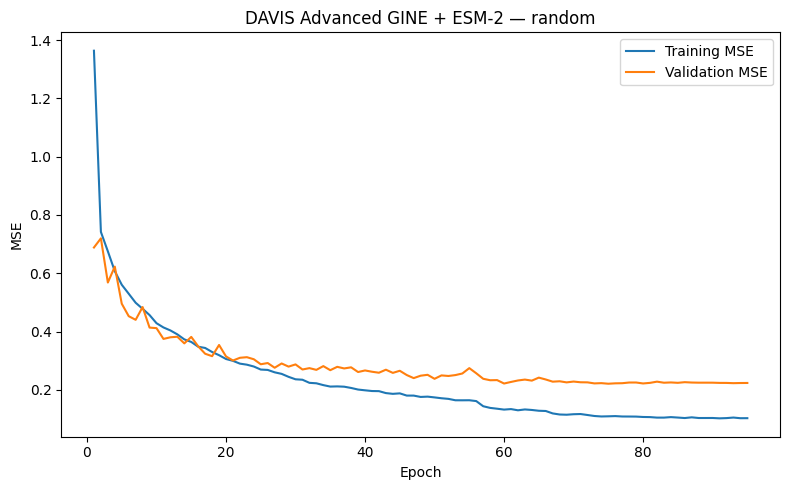


Best epoch: 75
Best validation MSE: 0.2210
Test RMSE: 0.5016
Test MAE: 0.2509
Concordance index: 0.8797
Pearson correlation: 0.8313


In [14]:
random_result = run_advanced_experiment(
    split_name="random",
    train_df=random_train_df,
    validation_df=random_validation_df,
    test_df=random_test_df,
)

## 13. Inspect random-split predictions

In [15]:
display(
    random_result["predictions"][
        [
            "drug_id",
            "target_id",
            "true_affinity",
            "predicted_affinity",
            "prediction_error",
        ]
    ].head(10)
)

,drug_id,target_id,true_affinity,predicted_affinity,prediction_error
0,24779724,ROCK2,5.000000,4.932509,-0.067491
1,11984591,PRKG1,5.000000,5.401968,0.401968
2,156414,PFCDPK1(Pfalciparum),5.000000,5.525195,0.525195
3,42642645,TSSK1B,5.000000,4.983949,-0.016051
4,126565,EPHA2,6.102373,5.698546,-0.403827
5,11626560,CLK3,5.000000,5.172615,0.172615
6,9926791,HIPK1,5.000000,5.193946,0.193946
7,156414,TTK,5.000000,5.096763,0.096763
8,11234052,PIK3CA(Q546K),5.000000,5.029003,0.029003
9,17755052,TAOK1,5.000000,5.124346,0.124346


# Part E — Cold-drug experiment

The cold-drug split contains no shared drugs between training, validation, and test partitions.

This experiment evaluates whether the advanced molecular encoder can generalise to compounds that were not observed during training.

## 14. Create and verify the cold-drug split

In [16]:
(
    cold_drug_train_df,
    cold_drug_validation_df,
    cold_drug_test_df,
) = cold_drug_split(
    davis_df,
    train_ratio=TRAIN_RATIO,
    validation_ratio=VALIDATION_RATIO,
    test_ratio=TEST_RATIO,
    seed=RANDOM_SEED,
)

print_split_summary(
    cold_drug_train_df,
    cold_drug_validation_df,
    cold_drug_test_df,
)

cold_drug_is_valid = check_cold_split(
    cold_drug_train_df,
    cold_drug_validation_df,
    cold_drug_test_df,
    column="drug_id",
)

print("No drug overlap:", cold_drug_is_valid)

assert cold_drug_is_valid, (
    "Cold-drug split contains overlapping drugs."
)

,partition,interactions,unique_drugs,unique_targets
0,Train,23868,54,442
1,Validation,2652,6,442
2,Test,3536,8,442


No drug overlap: True


## 15. Train and evaluate the advanced model on the cold-drug split

Running split: cold_drug
------------------------------------------------------------
Trainable parameters: 1,139,463
Epoch 001 | Train MSE: 1.4354 | Validation MSE: 0.7094
Epoch 002 | Train MSE: 0.7595 | Validation MSE: 0.7542
Epoch 003 | Train MSE: 0.6986 | Validation MSE: 0.6777
Epoch 004 | Train MSE: 0.6494 | Validation MSE: 0.6818
Epoch 005 | Train MSE: 0.6023 | Validation MSE: 0.6486
Epoch 006 | Train MSE: 0.5673 | Validation MSE: 0.7127
Epoch 007 | Train MSE: 0.5344 | Validation MSE: 0.6140
Epoch 008 | Train MSE: 0.5112 | Validation MSE: 0.6839
Epoch 009 | Train MSE: 0.4833 | Validation MSE: 0.6689
Epoch 010 | Train MSE: 0.4575 | Validation MSE: 0.6405
Epoch 011 | Train MSE: 0.4404 | Validation MSE: 0.7182
Epoch 012 | Train MSE: 0.4206 | Validation MSE: 0.6380
Epoch 013 | Train MSE: 0.4047 | Validation MSE: 0.5971
Epoch 014 | Train MSE: 0.3839 | Validation MSE: 0.6373
Epoch 015 | Train MSE: 0.3736 | Validation MSE: 0.6300
Epoch 016 | Train MSE: 0.3619 | Validation MSE: 0.5966
Ep

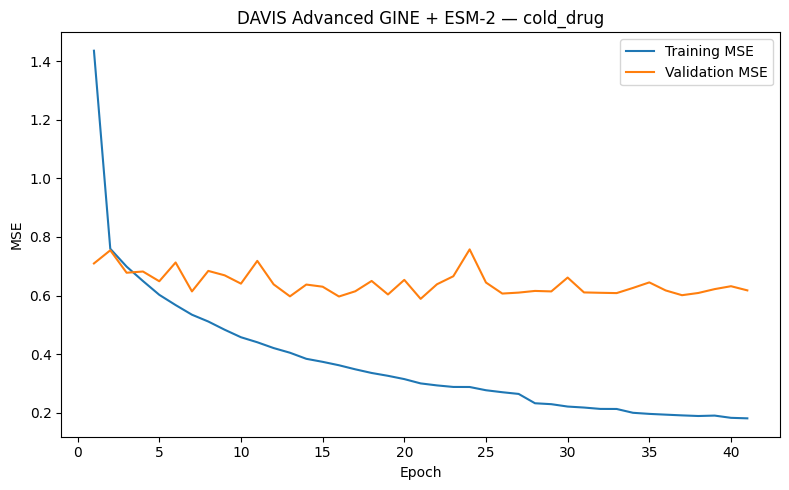


Best epoch: 21
Best validation MSE: 0.5885
Test RMSE: 0.9087
Test MAE: 0.5493
Concordance index: 0.8073
Pearson correlation: 0.6107


In [17]:
cold_drug_result = run_advanced_experiment(
    split_name="cold_drug",
    train_df=cold_drug_train_df,
    validation_df=cold_drug_validation_df,
    test_df=cold_drug_test_df,
)

## 16. Inspect cold-drug predictions

In [18]:
display(
    cold_drug_result["predictions"][
        [
            "drug_id",
            "target_id",
            "true_affinity",
            "predicted_affinity",
            "prediction_error",
        ]
    ].head(10)
)

,drug_id,target_id,true_affinity,predicted_affinity,prediction_error
0,9926054,AAK1,5.0,5.022548,0.022548
1,9926054,ABL1(E255K),5.0,4.985305,-0.014695
2,9926054,ABL1(F317I),5.0,4.985305,-0.014695
3,9926054,ABL1(F317I)p,5.0,4.985305,-0.014695
4,9926054,ABL1(F317L),5.0,4.985305,-0.014695
5,9926054,ABL1(F317L)p,5.0,4.985305,-0.014695
6,9926054,ABL1(H396P),5.0,4.985305,-0.014695
7,9926054,ABL1(H396P)p,5.0,4.985305,-0.014695
8,9926054,ABL1(M351T),5.0,4.985305,-0.014695
9,9926054,ABL1(Q252H),5.0,4.985305,-0.014695


# Part F — Cold-target experiment

The cold-target split contains no shared protein targets between training, validation, and test partitions.

This is especially relevant to the advanced model because the protein branch uses pretrained frozen ESM-2 residue representations before task-specific CNN and cross-attention processing.

## 17. Create and verify the cold-target split

In [19]:
(
    cold_target_train_df,
    cold_target_validation_df,
    cold_target_test_df,
) = cold_target_split(
    davis_df,
    train_ratio=TRAIN_RATIO,
    validation_ratio=VALIDATION_RATIO,
    test_ratio=TEST_RATIO,
    seed=RANDOM_SEED,
)

print_split_summary(
    cold_target_train_df,
    cold_target_validation_df,
    cold_target_test_df,
)

cold_target_is_valid = check_cold_split(
    cold_target_train_df,
    cold_target_validation_df,
    cold_target_test_df,
    column="target_id",
)

print(
    "No target overlap:",
    cold_target_is_valid,
)

assert cold_target_is_valid, (
    "Cold-target split contains overlapping targets."
)

,partition,interactions,unique_drugs,unique_targets
0,Train,24004,68,353
1,Validation,2992,68,44
2,Test,3060,68,45


No target overlap: True


## 18. Train and evaluate the advanced model on the cold-target split

Running split: cold_target
------------------------------------------------------------
Trainable parameters: 1,139,463
Epoch 001 | Train MSE: 1.3912 | Validation MSE: 0.8496
Epoch 002 | Train MSE: 0.7109 | Validation MSE: 0.6809
Epoch 003 | Train MSE: 0.6316 | Validation MSE: 0.6452
Epoch 004 | Train MSE: 0.5696 | Validation MSE: 0.5540
Epoch 005 | Train MSE: 0.5402 | Validation MSE: 0.5244
Epoch 006 | Train MSE: 0.5111 | Validation MSE: 0.5157
Epoch 007 | Train MSE: 0.4817 | Validation MSE: 0.4867
Epoch 008 | Train MSE: 0.4529 | Validation MSE: 0.5093
Epoch 009 | Train MSE: 0.4384 | Validation MSE: 0.4556
Epoch 010 | Train MSE: 0.4187 | Validation MSE: 0.4650
Epoch 011 | Train MSE: 0.4004 | Validation MSE: 0.4148
Epoch 012 | Train MSE: 0.3856 | Validation MSE: 0.4457
Epoch 013 | Train MSE: 0.3739 | Validation MSE: 0.3794
Epoch 014 | Train MSE: 0.3633 | Validation MSE: 0.4015
Epoch 015 | Train MSE: 0.3496 | Validation MSE: 0.3724
Epoch 016 | Train MSE: 0.3413 | Validation MSE: 0.3762


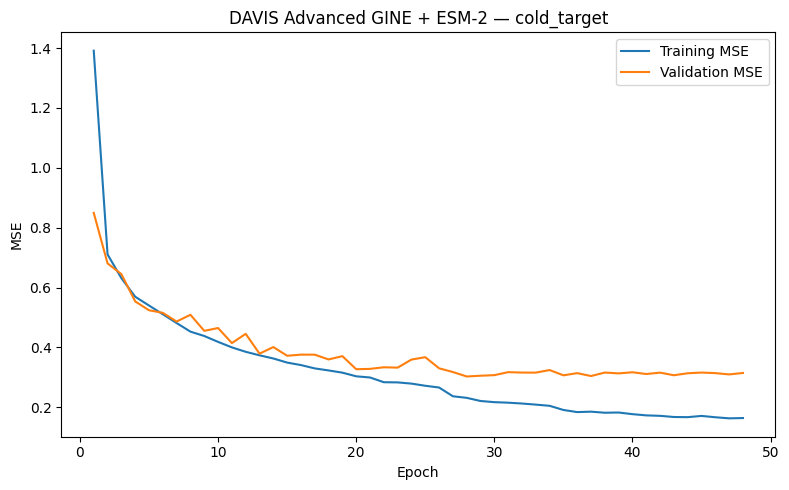


Best epoch: 28
Best validation MSE: 0.3032
Test RMSE: 0.6633
Test MAE: 0.3609
Concordance index: 0.8297
Pearson correlation: 0.7451


In [20]:
cold_target_result = run_advanced_experiment(
    split_name="cold_target",
    train_df=cold_target_train_df,
    validation_df=cold_target_validation_df,
    test_df=cold_target_test_df,
)

## 19. Inspect cold-target predictions

In [21]:
display(
    cold_target_result["predictions"][
        [
            "drug_id",
            "target_id",
            "true_affinity",
            "predicted_affinity",
            "prediction_error",
        ]
    ].head(10)
)

,drug_id,target_id,true_affinity,predicted_affinity,prediction_error
0,11314340,ABL1(H396P),5.000000,4.957751,-0.042249
1,11314340,ABL1,5.000000,4.957751,-0.042249
2,11314340,ABL1p,5.000000,4.957751,-0.042249
3,11314340,ABL2,5.000000,4.905102,-0.094898
4,11314340,ADCK3,5.000000,6.319964,1.319964
5,11314340,ADCK4,5.000000,5.830009,0.830009
6,11314340,AURKA,5.000000,5.181572,0.181572
7,11314340,AURKB,5.000000,5.291288,0.291288
8,11314340,AURKC,5.075721,5.408132,0.332411
9,11314340,BMPR1B,5.000000,4.910552,-0.089448


# Part G — Advanced-model results summary

The three advanced experiments are combined into one metrics file for later comparison with the three DAVIS baseline models.

## 20. Combine and save advanced-model metrics

In [22]:
advanced_results_df = pd.DataFrame(
    [
        random_result["result"],
        cold_drug_result["result"],
        cold_target_result["result"],
    ]
)

metrics_path = (
    METRICS_DIR
    / "davis_advanced_gine_esm2.csv"
)

advanced_results_df.to_csv(
    metrics_path,
    index=False,
)

display(
    advanced_results_df.round(4)
)

print("Metrics saved to:", metrics_path)

,dataset,model,split,best_epoch,completed_epochs,best_validation_mse,test_mse,test_rmse,test_mae,ci,pearson,trainable_parameters
0,DAVIS,GINE + frozen ESM-2 + CNN + cross-attention,random,75,95,0.2210,0.2516,0.5016,0.2509,0.8797,0.8313,1139463
1,DAVIS,GINE + frozen ESM-2 + CNN + cross-attention,cold_drug,21,41,0.5885,0.8258,0.9087,0.5493,0.8073,0.6107,1139463
2,DAVIS,GINE + frozen ESM-2 + CNN + cross-attention,cold_target,28,48,0.3032,0.4400,0.6633,0.3609,0.8297,0.7451,1139463


Metrics saved to: /content/final-msc-dissertation-drug-repurposing/results/metrics/davis_advanced_gine_esm2.csv


## 21. Compare test RMSE across the three splits

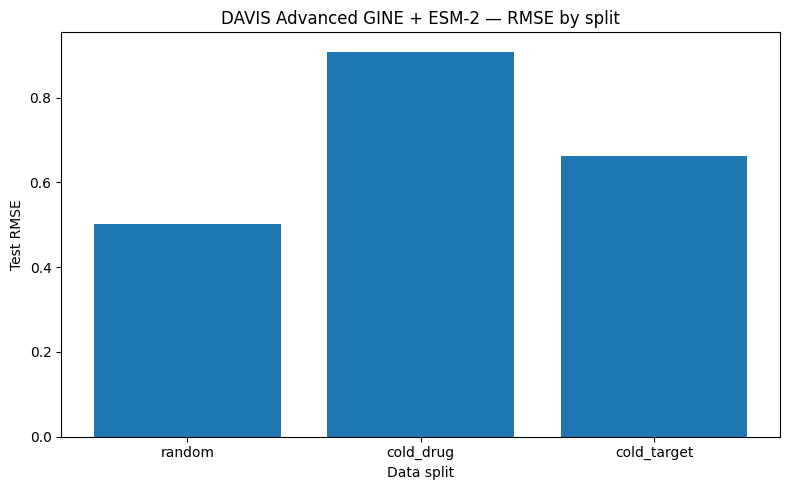

Comparison figure saved to: /content/final-msc-dissertation-drug-repurposing/results/figures/davis_advanced_gine_esm2_split_comparison.png


In [23]:
plt.figure(figsize=(8, 5))

plt.bar(
    advanced_results_df["split"],
    advanced_results_df["test_rmse"],
)

plt.xlabel("Data split")
plt.ylabel("Test RMSE")
plt.title(
    "DAVIS Advanced GINE + ESM-2 — RMSE by split"
)
plt.tight_layout()

comparison_figure_path = (
    FIGURES_DIR
    / "davis_advanced_gine_esm2_split_comparison.png"
)

plt.savefig(
    comparison_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    "Comparison figure saved to:",
    comparison_figure_path,
)

## 22. Final advanced-model summary

In [24]:
summary_columns = [
    "split",
    "best_epoch",
    "best_validation_mse",
    "test_rmse",
    "test_mae",
    "ci",
    "pearson",
]

final_summary = (
    advanced_results_df[
        summary_columns
    ]
    .sort_values("test_rmse")
    .reset_index(drop=True)
)

display(
    final_summary.round(4)
)

best_split = final_summary.iloc[0]

print(
    "Lowest advanced-model test RMSE:",
    best_split["split"],
    f'({best_split["test_rmse"]:.4f})',
)

print()
print("Saved outputs")
print("-" * 55)
print("Metrics:", metrics_path)
print(
    "Random predictions:",
    random_result["prediction_path"],
)
print(
    "Cold-drug predictions:",
    cold_drug_result["prediction_path"],
)
print(
    "Cold-target predictions:",
    cold_target_result["prediction_path"],
)
print("ESM-2 cache:", ESM_CACHE_PATH)
print("Figures folder:", FIGURES_DIR)
print("Checkpoints folder:", CHECKPOINTS_DIR)

,split,best_epoch,best_validation_mse,test_rmse,test_mae,ci,pearson
0,random,75,0.2210,0.5016,0.2509,0.8797,0.8313
1,cold_target,28,0.3032,0.6633,0.3609,0.8297,0.7451
2,cold_drug,21,0.5885,0.9087,0.5493,0.8073,0.6107


Lowest advanced-model test RMSE: random (0.5016)

Saved outputs
-------------------------------------------------------
Metrics: /content/final-msc-dissertation-drug-repurposing/results/metrics/davis_advanced_gine_esm2.csv
Random predictions: /content/final-msc-dissertation-drug-repurposing/results/predictions/davis_advanced_gine_esm2_random.csv
Cold-drug predictions: /content/final-msc-dissertation-drug-repurposing/results/predictions/davis_advanced_gine_esm2_cold_drug.csv
Cold-target predictions: /content/final-msc-dissertation-drug-repurposing/results/predictions/davis_advanced_gine_esm2_cold_target.csv
ESM-2 cache: /content/final-msc-dissertation-drug-repurposing/results/esm_embeddings/davis_esm2_t6_residue_embeddings.pt
Figures folder: /content/final-msc-dissertation-drug-repurposing/results/figures
Checkpoints folder: /content/final-msc-dissertation-drug-repurposing/results/checkpoints


### Notebook completion

This notebook completes the advanced DAVIS experiment using:

**4-layer GINE + frozen ESM-2 + 3-layer CNN + bidirectional cross-attention + attention pooling + MLP regression.**



In [25]:

from google.colab import runtime
runtime.unassign()